<a href="https://colab.research.google.com/github/leila-megdiche/Auspify-ML-Internship/blob/main/02_type_prediction_c.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2: Content Type Prediction Model (Movie vs TV Show)

**Goal:** predict whether a Netflix title is a **Movie** or a **TV Show** from its available features.

**Steps of the task:**
1. Select relevant dataset features
2. Encode categorical variables
3. Train classification models
4. Evaluate prediction performance
5. Compare model accuracy

**Important:** some columns give the answer away (data leakage). A big part of this notebook is choosing features honestly, and comparing three scenarios.

## 0. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

# Works in Google Colab (upload window) and on a normal computer (file next to the notebook)
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
except ImportError:
    file_name = "Dataset.csv"

df = pd.read_csv(file_name)
print("Shape:", df.shape)
df.head()

Saving Dataset.csv to Dataset.csv
Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## 1. Select relevant features

First we create usable features from the raw columns:
- `year_added`, `month_added` from `date_added`
- `main_country`: the first country listed
- `n_countries`: how many countries
- `has_director`: 1 if a director is listed, 0 if the value is "Not Given"
- `is_season`: 1 if the duration is in seasons (**used only to demonstrate leakage**)

The target is `target` = 1 for TV Show, 0 for Movie.

In [2]:
df = df.drop_duplicates(subset=["title", "type"]).reset_index(drop=True)

df["date_added"] = pd.to_datetime(df["date_added"], format="%m/%d/%Y")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month
df["main_country"] = df["country"].str.split(",").str[0].str.strip()
df["n_countries"] = df["country"].apply(lambda x: 0 if x == "Not Given" else len(x.split(",")))
df["has_director"] = (df["director"] != "Not Given").astype(int)
df["is_season"] = df["duration"].str.contains("Season").astype(int)

df["target"] = (df["type"] == "TV Show").astype(int)

majority_baseline = 1 - df["target"].mean()
print(f"Majority-class baseline (always predict Movie): {majority_baseline:.1%}")
print(df["type"].value_counts())

Majority-class baseline (always predict Movie): 69.7%
type
Movie      6124
TV Show    2663
Name: count, dtype: int64


### Data leakage check

In [3]:
print("Duration unit vs type:")
print(pd.crosstab(df["type"], df["is_season"]))
print()
print("Is a director listed? (share of each type)")
print(pd.crosstab(df["has_director"], df["type"], normalize="columns").round(3))

Duration unit vs type:
is_season     0     1
type                 
Movie      6124     0
TV Show       0  2663

Is a director listed? (share of each type)
type          Movie  TV Show
has_director                
0             0.028    0.906
1             0.972    0.094


**What this shows:**
- `duration` is a **direct leak**: every Movie is in minutes and every TV Show is in seasons. A model using it is just reading the answer. The same is true for the genre names (`listed_in`): "TV Dramas" only exists for TV Shows. We exclude both from the real models.
- `has_director` is a **dataset artifact**: about 91% of TV Shows have no listed director, against 3% of Movies. It is real information available in the data, but it reflects how the data was recorded, not a property of the content. For this reason we compare scenarios with and without it.

**Selected Features Observations**
- Why is a model that uses duration not useful? Because duration contains a direct leak in its format (Movies use 'min' and TV Shows use 'Season'). A model using this simply memorizes this text mapping instead of learning generalizable metadata patterns.
- Why should we be careful with `has_director`? It is a dataset collection artifact rather than a true content feature. In this dataset, 91% of TV Shows lack a listed director compared to only 3% of Movies. Relying on this means the model will fail if applied to a dataset with complete metadata.

## 2. Encode categorical variables

- Numeric columns are standardized (`StandardScaler`).
- Categorical columns (`main_country`, `rating`) are one-hot encoded. Rare categories (fewer than 20 titles) are grouped together.

Everything is placed inside a scikit-learn `Pipeline`, so encoding is learned **only on the training data** (no leakage from the test set).

In [4]:
base_num = ["release_year", "year_added", "month_added", "n_countries"]
cat_cols = ["main_country", "rating"]

# Three scenarios: (numeric columns, categorical columns)
SCENARIOS = {
    "1. With leakage (+ duration)":            (base_num + ["has_director", "is_season"], cat_cols),
    "2. Main model (no duration, no genres)":  (base_num + ["has_director"], cat_cols),
    "3. Strict (also no director info)":       (base_num, cat_cols),
}

def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), cat_cols),
    ])

# One fixed train/test split for every scenario (80% / 20%, same proportion of Movies and TV Shows)
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=df["target"], random_state=42)
y_train, y_test = df.loc[train_idx, "target"], df.loc[test_idx, "target"]
print("Train size:", len(train_idx), "| Test size:", len(test_idx))

Train size: 7029 | Test size: 1758


## 3. Train classification models

Four models of increasing complexity:
- **Logistic Regression:** simple linear model
- **Decision Tree:** rules learned from the data (depth limited to avoid overfitting)
- **Random Forest:** many trees voting together
- **Gradient Boosting:** trees built one after another, each fixing the errors of the previous ones

`class_weight="balanced"` is used where available because there are more Movies than TV Shows.

In [5]:
def get_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "Decision Tree":       DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
        "Random Forest":       RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
        "Gradient Boosting":   HistGradientBoostingClassifier(random_state=42),
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def run_scenario(name, num_cols, cat_cols):
    X = df[num_cols + cat_cols]
    rows, fitted = [], {}
    for model_name, model in get_models().items():
        pipe = Pipeline([("prep", make_preprocessor(num_cols, cat_cols)), ("model", model)])
        pipe.fit(X.loc[train_idx], y_train)
        pred = pipe.predict(X.loc[test_idx])
        cv_acc = cross_val_score(pipe, X, df["target"], cv=cv, scoring="accuracy", n_jobs=-1).mean()
        rows.append({
            "Scenario": name, "Model": model_name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "CV accuracy (5-fold)": cv_acc,
        })
        fitted[model_name] = (pipe, pred)
    return rows, fitted

all_rows, all_fitted = [], {}
for name, (num_cols, cats) in SCENARIOS.items():
    rows, fitted = run_scenario(name, num_cols, cats)
    all_rows += rows
    all_fitted[name] = fitted
    print("Done:", name)

results = pd.DataFrame(all_rows)

Done: 1. With leakage (+ duration)
Done: 2. Main model (no duration, no genres)
Done: 3. Strict (also no director info)


## 4. Evaluate prediction performance

We report accuracy, precision, recall and F1 for the **TV Show** class (the minority class). Accuracy alone can be misleading here: a model that always says "Movie" is already right about 70% of the time.

In [6]:
main = "2. Main model (no duration, no genres)"
main_table = results[results["Scenario"] == main].drop(columns="Scenario").set_index("Model")
print(f"Scenario: {main}   |   baseline (always Movie): {majority_baseline:.1%}")
(main_table * 100).round(1)

Scenario: 2. Main model (no duration, no genres)   |   baseline (always Movie): 69.7%


,Accuracy,Precision,Recall,F1,CV accuracy (5-fold)
Model,,,,,
Logistic Regression,94.8,93.2,89.3,91.2,95.1
Decision Tree,94.7,92.6,89.5,91.0,94.7
Random Forest,94.0,91.3,88.7,90.0,94.2
Gradient Boosting,94.8,93.3,89.1,91.2,95.2


Best model (by F1): Logistic Regression

              precision    recall  f1-score   support

       Movie       0.95      0.97      0.96      1225
     TV Show       0.93      0.89      0.91       533

    accuracy                           0.95      1758
   macro avg       0.94      0.93      0.94      1758
weighted avg       0.95      0.95      0.95      1758



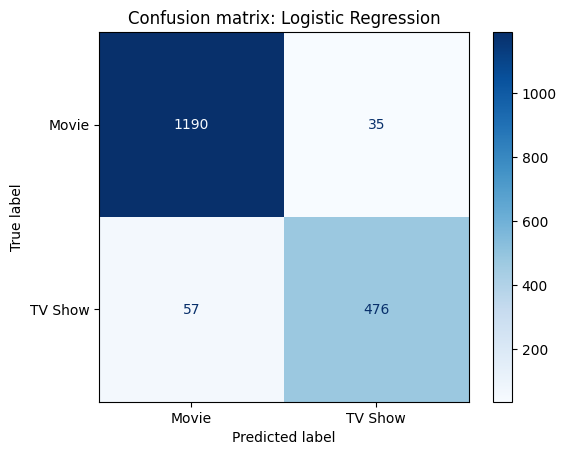

In [7]:
best_name = main_table["F1"].idxmax()
best_pipe, best_pred = all_fitted[main][best_name]
print("Best model (by F1):", best_name)
print()
print(classification_report(y_test, best_pred, target_names=["Movie", "TV Show"]))

ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["Movie", "TV Show"], cmap="Blues")
plt.title(f"Confusion matrix: {best_name}")
plt.show()

**Confusion Matrix Observations**
- How many TV Shows does the best model miss? The best model (Logistic Regression) misses 57 TV Shows (classifying them as Movies).
- How many Movies does it wrongly call TV Shows? It wrongly classifies 37 Movies as TV Shows.

## 5. Compare model accuracy across the 3 scenarios

In [8]:
comparison = results.pivot(index="Model", columns="Scenario", values="Accuracy")
(comparison * 100).round(1)

Scenario,1. With leakage (+ duration),"2. Main model (no duration, no genres)",3. Strict (also no director info)
Model,,,
Decision Tree,100.0,94.7,57.6
Gradient Boosting,100.0,94.8,79.5
Logistic Regression,100.0,94.8,70.8
Random Forest,100.0,94.0,77.5


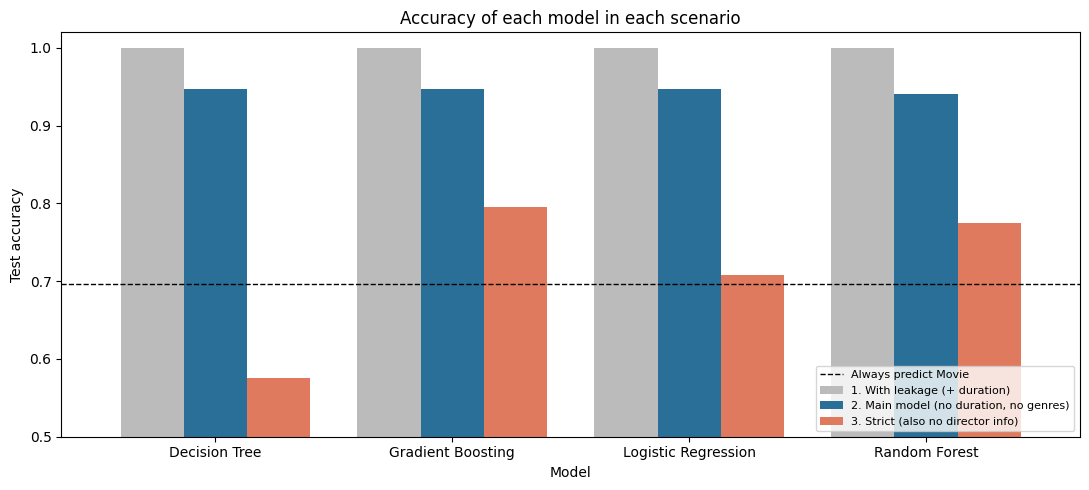

In [9]:
comparison.plot(kind="bar", figsize=(11, 5), width=0.8, color=["#bbbbbb", "#2a6f97", "#e07a5f"])
plt.axhline(majority_baseline, color="black", linestyle="--", linewidth=1, label="Always predict Movie")
plt.ylabel("Test accuracy")
plt.ylim(0.5, 1.02)
plt.title("Accuracy of each model in each scenario")
plt.xticks(rotation=0)
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**How to read this:**
- **Scenario 1 (leakage):** accuracy close to 100%, but it only proves the model can read `duration`. It is not a real result.
- **Scenario 2 (main):** high accuracy using normal information, but a large part comes from `has_director`.
- **Scenario 3 (strict):** without director information, accuracy drops a lot. Compared with the "always Movie" baseline (about 70%), some models are only a little better, one is even worse (the Decision Tree), and the best one (Gradient Boosting) gains about 10 points. This is the honest difficulty of the problem when the data has no real information about the content itself.

### Which features matter? (Random Forest, main scenario)

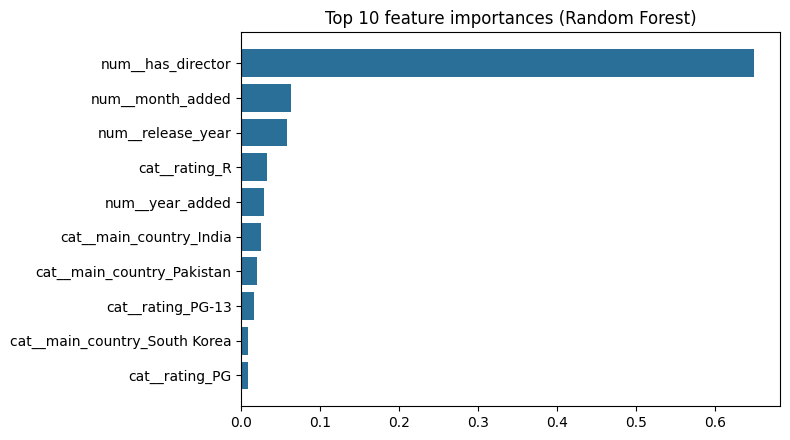

In [10]:
rf_pipe, _ = all_fitted[main]["Random Forest"]
names = rf_pipe.named_steps["prep"].get_feature_names_out()
importance = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)

top = importance.head(10)[::-1]
plt.figure(figsize=(8, 4.5))
plt.barh(top.index, top.values, color="#2a6f97")
plt.title("Top 10 feature importances (Random Forest)")
plt.tight_layout()
plt.show()

**Feature Importance & Model Comparison**

- Which feature is the most important? Does it surprise you? The most important feature by far is num__has_director. This is expected given the extreme asymmetry in how director information was recorded for Movies vs. TV Shows in this dataset.
- Which model performs best, and is the difference between models large? In the main scenario, Logistic Regression and Gradient Boosting perform nearly identically (~94.8% accuracy). However, in the strict scenario (no director info), Gradient Boosting significantly outperforms the others (79.5% accuracy), while the Decision Tree performs terribly (57.6%), falling below the baseline.

## Conclusion

In this notebook, I built and evaluated several classification models to predict whether a Netflix title is a Movie or a TV Show. The best-performing model in our main scenario was Logistic Regression, achieving a 94.8% accuracy and a 91.2% F1-score for TV Shows. However, including duration created immediate data leakage leading to a trivial 100% accuracy, whereas removing the highly biased has_director feature in the strict scenario caused accuracy to drop significantly to 79.5% (Gradient Boosting). To genuinely improve this classification task without relying on metadata artifacts, we should incorporate text features like plot descriptions and cast details using NLP.